# SAMI: a few extra checks

**Questions:** Does the measurement aperture change the relation? Why might galaxy size change the dispersion? What happens if the stellar-mass scale changes? What do the residuals tell us?

This notebook uses the shared early-type sample from `02_sample_selection.ipynb` (`../data/processed/sample_early_types.csv`), so run notebooks 01 and 02 first. Run it from the top with `notebooks/` as the working directory.

There are three kinds of calculation here: an **aperture comparison** and **residual checks** on the actual sample, a **size illustration** from the virial theorem, and a **hypothetical mass-scale sensitivity check**. The illustration is not an extra observation of the SAMI galaxies.

## Where the methods come from

| Code operation | Supplied teaching example |
|---|---|
| Variables, lists, arithmetic including `**`, indexing, `print`, `len` | Tutorial 1; Spotted Python Week 2 |
| `pd.read_csv`, named columns, `pd.DataFrame` | Tutorial 2: Pandas and Markdown |
| `value_counts`, Boolean masks with `&` / `\|` | Tutorial 1 solutions; Tutorial 4 selections |
| `np.array`, `np.sum` | Spotted Python Week 2 solutions, cells 25 and 38 |
| `np.log` and array arithmetic | Tutorial 4 and Spotted Python Week 3 |
| `np.linspace` | Spotted Python Week 4, ellipticity grid example |
| `stats.linregress`, slope, intercept, standard errors, `rvalue` | Tutorial 4 solutions, linear-fitting example |
| `plt.subplots`, `plt.plot`, labels, title, legend, `tight_layout`, `show` | Tutorial plotting examples; Spotted Python Week 4 |


## Start with the same galaxies

`mstar` is already log10 stellar mass in solar units. Here `sigma` will mean log10 dispersion, while `sample['sigma_re']` remains the measured dispersion in km/s. The repeat check should give zero; stop if it does not. Notebook 02 is responsible for the measurement and morphology cuts.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

sample = pd.read_csv('../data/processed/sample_early_types.csv')
ids = sample['catid'].value_counts()
print('Galaxies:', len(sample))
print('Repeated IDs:', len(ids[ids > 1]))

mass = np.array(sample['mstar'])
sigma = np.log(np.array(sample['sigma_re'])) / np.log(10)
fit = stats.linregress(mass, sigma)
line = fit.slope * mass + fit.intercept

print('Slope:', fit.slope, '+/-', fit.stderr)
print('Intercept:', fit.intercept, '+/-', fit.intercept_stderr)


Galaxies: 768
Repeated IDs: 0
Slope: 0.3421833108948573 +/- 0.007847991156587127
Intercept: -1.4386821069372933 +/- 0.08253272237511794


## 1. Does the measurement aperture change the relation?

We compare velocity dispersion within the effective-radius aperture
with dispersion within a fixed 3-kpc aperture.

Both fits use the same galaxies with valid measurements in both
apertures. This lets us compare the apertures without also changing
which galaxies are fitted.

In [2]:
paired = sample[
    (sample['sigma_re'] > 0) &
    (sample['sigma_re_err'] > 0) &
    (sample['sigma_3kpc_round'] > 0) &
    (sample['sigma_3kpc_round_err'] > 0)
]

print('Main sample:', len(sample))
print('Galaxies with both apertures:', len(paired))
print('Removed from aperture comparison:', len(sample) - len(paired))

paired_mass = np.array(paired['mstar'])

sigma_re = np.log(np.array(paired['sigma_re'])) / np.log(10)
sigma_3kpc = np.log(np.array(paired['sigma_3kpc_round'])) / np.log(10)

fit_re = stats.linregress(paired_mass, sigma_re)
fit_3kpc = stats.linregress(paired_mass, sigma_3kpc)

print('Effective-radius slope:', fit_re.slope, '+/-', fit_re.stderr)
print('3-kpc slope:', fit_3kpc.slope, '+/-', fit_3kpc.stderr)
print('Slope difference:', fit_3kpc.slope - fit_re.slope)

Main sample: 768
Galaxies with both apertures: 767
Removed from aperture comparison: 1
Effective-radius slope: 0.3421529172216498 +/- 0.00792946620114389
3-kpc slope: 0.3576645401612276 +/- 0.007722023165086156
Slope difference: 0.015511622939577807


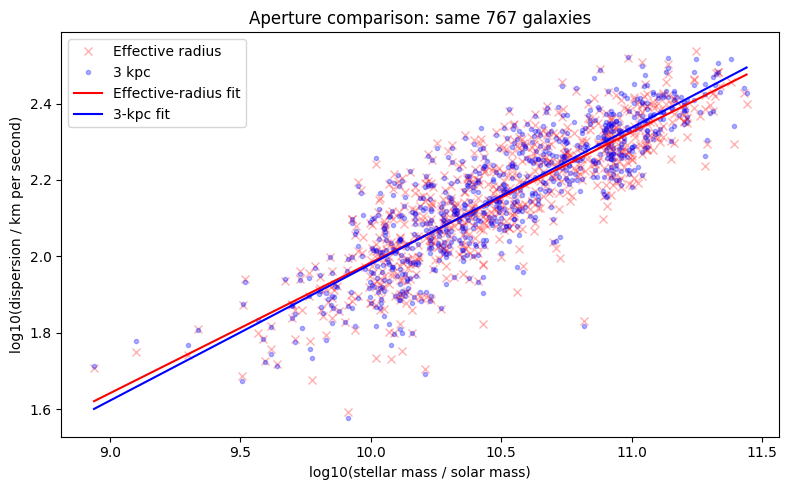

In [3]:
mass_line = np.linspace(paired_mass.min(), paired_mass.max(), 100)

line_re = fit_re.slope * mass_line + fit_re.intercept
line_3kpc = fit_3kpc.slope * mass_line + fit_3kpc.intercept

fig, ax = plt.subplots(figsize=(8, 5))

plt.plot(paired_mass, sigma_re, 'x', color='red',
         alpha=0.3, label='Effective radius')
plt.plot(paired_mass, sigma_3kpc, '.', color='blue',
         alpha=0.3, label='3 kpc')

plt.plot(mass_line, line_re, color='red',
         label='Effective-radius fit')
plt.plot(mass_line, line_3kpc, color='blue',
         label='3-kpc fit')

plt.xlabel('log10(stellar mass / solar mass)')
plt.ylabel('log10(dispersion / km per second)')
plt.title('Aperture comparison: same 767 galaxies')
plt.legend()
plt.tight_layout()
plt.show()

## 2. Why galaxy size matters

The virial theorem gives the scaling

$$\sigma^2\sim\frac{G M_{\rm dyn}}{R}.$$

For similar structure and velocity distributions, keeping the gravitating mass fixed gives

$$\frac{\sigma}{\sigma_0}=\left(\frac{R_0}{R}\right)^{1/2}.$$

This is a ratio calculation: the common mass and gravitational constant cancel. A radius ratio of 2 means twice the reference size. The corresponding dispersion ratio is $1/\sqrt{2}\simeq0.707$. For example, a 4 kpc system has twice the **mean square speed** of an 8 kpc system with the same mass, not twice the speed.

**What this checks:** can galaxies at the same gravitating mass have different dispersions just because their sizes differ? The model says yes. It does not establish that size causes the measured scatter in our stellar-mass relation. Stellar mass is not identical to total gravitating mass, and observed aperture dispersion is not automatically the global velocity scale in the virial theorem.


Dispersion ratio if the radius doubles: 0.7071067811865476
Speed ratio for the 4 kpc and 8 kpc example: 1.4142135623730951


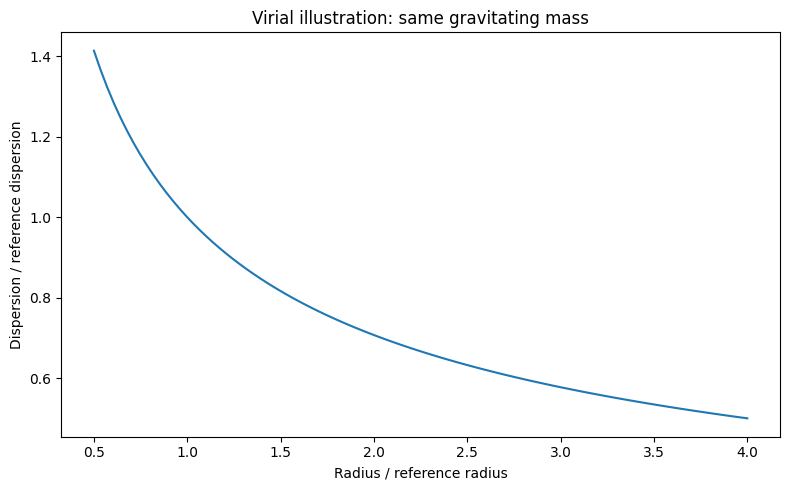

In [4]:
radius_ratio = np.linspace(0.5, 4, 100)
sigma_ratio = (1 / radius_ratio) ** 0.5

print('Dispersion ratio if the radius doubles:', (1 / 2) ** 0.5)
print('Speed ratio for the 4 kpc and 8 kpc example:', (8 / 4) ** 0.5)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(radius_ratio, sigma_ratio)
plt.xlabel('Radius / reference radius')
plt.ylabel('Dispersion / reference dispersion')
plt.title('Virial illustration: same gravitating mass')
plt.tight_layout()
plt.show()


**Before trying this with the actual catalogue:** both input schemas define `r_e` as an r-band major-axis effective radius in **arcseconds**. It is an angular light radius, not a radius in kpc or a measured half-mass radius. A physically large, distant galaxy can look small on the sky. Do not put `r_e` straight into a kpc calculation or interpret a raw `r_e`–dispersion trend as a physical-size result.

A proper observational follow-up would need justified physical radii, a stated distance conversion and control for stellar mass. None is introduced here. This is also why a size term appears in the Fundamental Plane; we do not fit a Fundamental Plane in this notebook.

**Check to explain:** if mass and structure stay fixed but radius halves, what happens to dispersion? The prediction is a factor $\sqrt{2}$ increase, not a factor 2 increase.


## 3. How assumptions about stellar mass could affect the fit

The mass-to-light relation is

$$M_\star=(M_\star/L)L.$$

The inferred mass-to-light ratio depends on the stellar population. The IMF, stellar ages, metallicities and modelling assumptions matter. As a simple population ages, its luminosity and colours evolve; its mass-to-light ratio can change. The supplied SAMI schemas do not specify all the assumptions behind each catalogue mass, so this notebook does not infer or correct their IMF.

Here is one **hypothetical sensitivity check**: what if all stellar masses were larger by a factor of 2? This factor is chosen to make the algebra easy to see. It is **not** a measured mass error, an uncertainty interval, or a conversion between named IMFs.

Because the code already uses logarithmic mass,

$$x'=\log_{10}(2M_\star)=x+\log_{10}2.$$

If $y=ax+b$, substituting $x=x'-\log_{10}2$ gives

$$y=ax'+\bigl(b-a\log_{10}2\bigr).$$

A uniform mass rescaling changes the intercept and leaves the slope unchanged. The next cell tests that using the actual sample. A correction that varies from galaxy to galaxy could affect the slope or scatter; a uniform shift cannot test that possibility.


Original slope: 0.3421833108948573
Shifted-mass slope: 0.3421833108948573
Original intercept: -1.4386821069372933
Shifted-mass intercept: -1.541689547532259


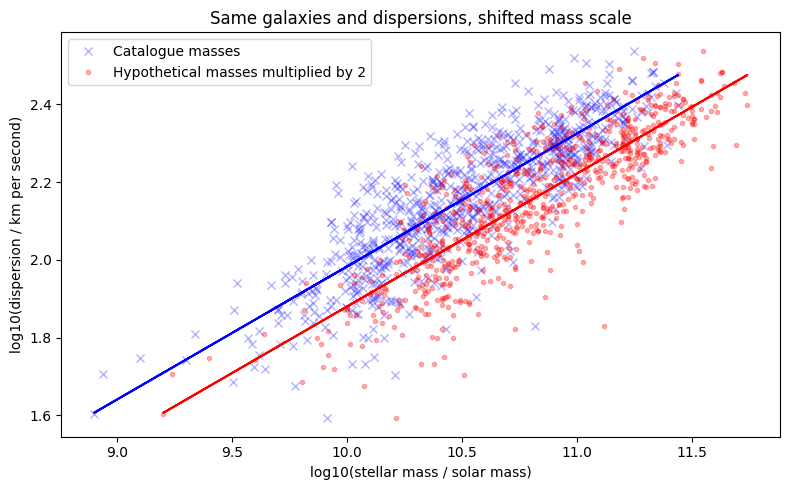

In [5]:
factor = 2
shifted_mass = mass + np.log(factor) / np.log(10)
shifted_fit = stats.linregress(shifted_mass, sigma)
shifted_line = shifted_fit.slope * shifted_mass + shifted_fit.intercept

print('Original slope:', fit.slope)
print('Shifted-mass slope:', shifted_fit.slope)
print('Original intercept:', fit.intercept)
print('Shifted-mass intercept:', shifted_fit.intercept)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(mass, sigma, 'x', alpha=0.3, color='blue', label='Catalogue masses')
plt.plot(shifted_mass, sigma, '.', alpha=0.3, color='red', label='Hypothetical masses multiplied by 2')
plt.plot(mass, line, color='blue')
plt.plot(shifted_mass, shifted_line, color='red')
plt.xlabel('log10(stellar mass / solar mass)')
plt.ylabel('log10(dispersion / km per second)')
plt.title('Same galaxies and dispersions, shifted mass scale')
plt.legend()
plt.tight_layout()
plt.show()


The shift is about 0.301 dex. For our sample, the slope stays at 0.342, while the intercept moves from −1.439 to −1.542. The original `mass` array and catalogue CSV have not been changed. A tiny numerical difference between the printed slopes is floating-point rounding.

**Checks for a literature comparison:** are the mass definitions and population assumptions comparable? Are the same aperture, galaxy selection and fitting direction used? The Oh et al. (2020) relation uses bulge-dominated galaxies ($B/T>0.8$); our E, E/S0 and S0 morphology cut does not recreate that selection. If both studies' mass scales were recalibrated, both relations would need consistent treatment. Do not attribute the observed slope difference to a uniform mass offset: this calculation shows why that alone cannot change the slope.


## 4. What does the fitted line miss?

We calculate residuals for the full main sample using the
effective-radius velocity dispersion.

Residual = observed log dispersion − predicted log dispersion.

Positive residuals mean higher dispersion than predicted.
Negative residuals mean lower dispersion than predicted.

Galaxies: 768
Residual RMS: 0.09110049715914115 dex


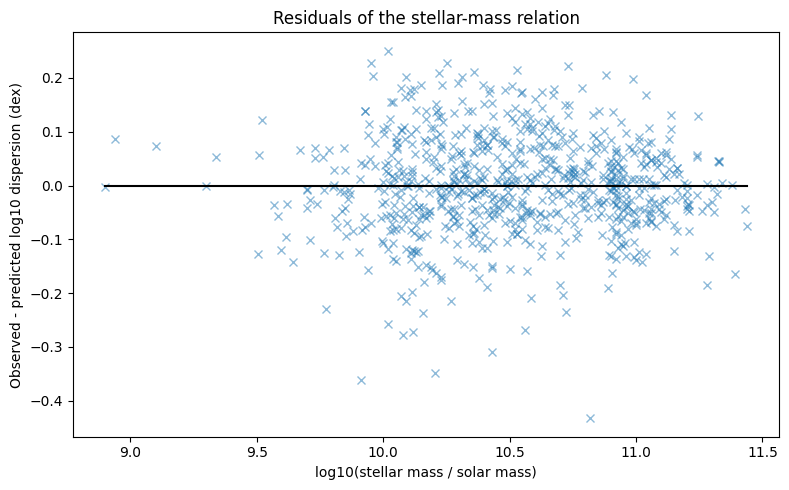

In [6]:
mass = np.array(sample['mstar'])
log_sigma = np.log(np.array(sample['sigma_re'])) / np.log(10)

residual_fit = stats.linregress(mass, log_sigma)
predicted = residual_fit.slope * mass + residual_fit.intercept

residual = log_sigma - predicted

rms = (np.sum(residual ** 2) / len(residual)) ** 0.5

print('Galaxies:', len(sample))
print('Residual RMS:', rms, 'dex')

fig, ax = plt.subplots(figsize=(8, 5))

plt.plot(mass, residual, 'x', alpha=0.5)
plt.plot([mass.min(), mass.max()], [0, 0], color='black')

plt.xlabel('log10(stellar mass / solar mass)')
plt.ylabel('Observed - predicted log10 dispersion (dex)')
plt.title('Residuals of the stellar-mass relation')
plt.tight_layout()
plt.show()